# Código TP2: Selección de Variables

In [5]:
from typing import Any, Callable, Dict, List
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score, LeaveOneOut
from sklearn.svm import LinearSVC
from sklearn.utils import resample
from scipy.stats import kruskal
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Ejercicio 1

## Función general de uso de distintos métodos para forward ranking

In [6]:
def forward_ranking(
        X: np.ndarray, y: np.ndarray,
        method: Callable[[np.ndarray, np.ndarray, Dict[str, Any]], float],
        verbosity: int = 0, **kwargs) -> List[int]:
    """
    Método Wrapper Forward Selection/Ranking.
    Comienza con una lista vacía e iterativamente añade la variable que junto
    a las ya seleccionadas retorna el menor error según el método provisto
    como argumento.

    Argumentos:
        X: lista de N inputs de dimensión M como array numpy de shape (N, M).
        y: lista de N targets como array numpy de shape (N,).
        method: función que estima el classification error para un clasificador
            dado con los datos dados; debe poder tomar una lista de inputs y
            una lista de targets y los argumentos pasados por "**kwargs", y
            devolver el error del modelo en el intervalo ( 0 , 1 ).
        verbosity: nivel de verbosidad de 0 a 3 que controla cuanta información
            se imprime por pantalla; a mayor número, más información imprime.
        **kwargs: parámetros adicionales a pasarle a la función de estimación.

    Retorna:
        orden de importancia de las variables (descendiente, numeradas desde cero)
    """
    _, max_feat = X.shape  # total de features
    num_feat = 0           # numero actual de features
    # lista para guardar los features elegidos, inicializo como llegaron
    list_feat = np.arange(0, max_feat)

    # ranking inicial: eijo la variable con menor error de predicción
    class_error = np.zeros(max_feat)
    # para cada indice i creo el dataset con la variable sola, entreno el
    # modelo, y le mido el error, que lo guardo en class_error[i]
    for i in range(max_feat):
        X_train = X[:, [i]]  # preservamos estructura de matriz
        class_error[i] = method(X_train, y, **kwargs)

    if verbosity > 2:
        print(f'\nIndividual Classes Error:\n{class_error}')

    # guardo la variable con mínimo error como primera en mi lista de elegidas
    # guardo una lista keep_feat con las que me quedan para seguir eligiendo
    list_feat[0] = np.argmin(class_error)
    keep_feat = np.argsort(class_error)
    keep_feat = keep_feat[keep_feat != list_feat[0]]
    num_feat += 1

    if verbosity > 1:
        print(f'\nFirst feature: {list_feat[0]}')

    # loop principal
    # a cada paso agrego todas las variables disponibles, de a una, les mido el
    # error y me quedo con la de mínimo error hasta llegar a meter todas
    while num_feat < max_feat:
        class_error = np.zeros(max_feat - num_feat)

        # class_error guarda el error de cada modelo restante
        for i in range(max_feat - num_feat):
            features = np.concatenate((list_feat[0:num_feat], [keep_feat[i]]))
            X_train = X[:, features]
            class_error[i] = method(X_train, y, **kwargs)

        if verbosity > 2:
            print(f'\nFeatures:\n{keep_feat}\nErrors:\n{class_error}')

        # me quedo con el modelo de minimo error, guardo ese feature en la lista
        # de las elegidas, lo saco de la lista de las que me quedan
        best_index = np.argmin(class_error)
        list_feat[num_feat] = keep_feat[best_index]

        if verbosity > 1:
            print(f'\n------------\nStep {num_feat+1}\nFeature {best_index}')

        keep_feat = np.delete(keep_feat, best_index)

        if verbosity > 2:
            print(f'\nNew search list {keep_feat}')

        num_feat += 1

    if verbosity > 1:
        print(f'\n------------\nFinal ranking of features: {list_feat}\n')

    return list_feat


In [7]:
def backward_ranking(
        X: np.ndarray, y: np.ndarray,
        method: Callable[[np.ndarray, np.ndarray, Dict[str, Any]], float],
        verbosity: int = 0, **kwargs) -> List[int]:
    """
    Método Wrapper Backward Selection/Ranking.
    Comienza con todas las variables e iterativamente elimina la variable cuya
    ausencia retorna el menor error según el método provisto como argumento.
    Argumentos:
        X: lista de N inputs de dimensión M como array numpy de shape (N, M).
        y: lista de N targets como array numpy de shape (N,).
        method: función que estima el classification error para un clasificador
            dado con los datos dados; debe poder tomar una lista de inputs y
            una lista de targets y los argumentos pasados por "**kwargs", y
            devolver el error del modelo en el intervalo ( 0 , 1 ).
        verbosity: nivel de verbosidad de 0 a 3 que controla cuanta información
            se imprime por pantalla; a mayor número, más información imprime.
        **kwargs: parámetros adicionales a pasarle a la función de estimación.

    Retorna:
        orden de importancia de las variables (descendiente, numeradas desde cero)
    """
    _, max_feat = X.shape  # total de features
    keep_feat = np.arange(0, max_feat)
    list_feat = np.zeros(max_feat, dtype=int)

    while len(keep_feat) > 1:
        class_error = np.zeros(len(keep_feat))

        for i in range(len(keep_feat)):
            features = np.delete(keep_feat, i)
            X_train = X[:, features]
            class_error[i] = method(X_train, y, **kwargs)

        if verbosity > 2:
            print(f'\nFeatures:\n{keep_feat}\nErrors without each one:\n{class_error}')

        # elimino por posición la variable cuya ausencia da el
        # menor error; se ubica en el último lugar libre del ranking
        worst_index = np.argmin(class_error)
        list_feat[len(keep_feat) - 1] = keep_feat[worst_index]

        if verbosity > 1:
            print(f'\n------------\nStep {max_feat - len(keep_feat) + 1}'
                  f'\nRemoved feature {keep_feat[worst_index]}')

        keep_feat = np.delete(keep_feat, worst_index)

    # la única variable que sobrevive es la más importante
    list_feat[0] = keep_feat[0]

    if verbosity > 1:
        print(f'\n------------\nFinal ranking of features: {list_feat}\n')

    return list_feat


In [8]:
def kruskal_wallis_ranking(X: np.ndarray, y: np.ndarray):
    """
    Filter con test no paramétrico de Kruskal-Wallis.
    Retorna orden de importancia (descendente).
    """
    clases = np.unique(y)
    H = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        grupos = [X[y == c, j] for c in clases]
        H[j], _ = kruskal(*grupos)
    orden = np.argsort(-H)
    return orden

In [9]:
def recursive_feature_elimination_ranking(
        X: np.ndarray, y: np.ndarray,
        method: Callable[[np.ndarray, np.ndarray, Dict[str, Any]], Any],
        verbosity: int = 0, **kwargs) -> List[int]:
    """
    Método Recursive Feature Elimination (RFE) Ranking.
    Comienza con todas las variables e iterativamente entrena un modelo con las
    variables restantes, mide la importancia de cada una según el método
    provisto como argumento, y elimina la menos importante.

    Argumentos:
        X: lista de N inputs de dimensión M como array numpy de shape (N, M).
        y: lista de N targets como array numpy de shape (N,).
        method: función que entrena un modelo y calcula la importancia de cada
            variable; debe poder tomar una lista de inputs y una lista de
            targets y los argumentos pasados por "**kwargs", y devolver una
            tupla (feats, imp) con los índices de las columnas de X ordenados de
            menor a mayor importancia y las importancias en ese mismo orden.
        verbosity: nivel de verbosidad de 0 a 3 que controla cuanta información
            se imprime por pantalla; a mayor número, más información imprime.
        **kwargs: parámetros adicionales a pasarle a la función de ranking.

    Retorna:
        orden de importancia de las variables (descendiente, numeradas desde cero)
    """
    _, max_feat = X.shape  # total de features
    keep_feat = np.arange(0, max_feat)
    list_feat = np.zeros(max_feat, dtype=int)

    while len(keep_feat) > 1:
        feats, imp = method(X[:, keep_feat], y, **kwargs)

        if verbosity > 2:
            print(f'\nFeatures:\n{keep_feat[feats]}\nImportances:\n{imp}')

        worst_index = feats[0]
        list_feat[len(keep_feat) - 1] = keep_feat[worst_index]

        if verbosity > 1:
            print(f'\n------------\nStep {max_feat - len(keep_feat) + 1}'
                  f'\nRemoved feature {keep_feat[worst_index]}')

        keep_feat = np.delete(keep_feat, worst_index)

    list_feat[0] = keep_feat[0]

    if verbosity > 1:
        print(f'\n------------\nFinal ranking of features: {list_feat}\n')

    return list_feat

## Métodos para entrenamiento y estimación de error

In [10]:
def error_rate(A, B):
    """  Función de ayuda para calcular error """
    return sum(A != B) / len(B)


def RF_error_estimation(
        X, y, equalize_classes = True, total_trees = 500, mtry = 0):
    """
    Random forest error estimation (Out-Of-Bag) for greedy search
    """
    if mtry < 1:
        mtry = int(np.floor(np.sqrt(X.shape[1])))
    class_weights = None
    if equalize_classes:
        class_weights = 'balanced'
    random_forest = RandomForestClassifier(
        n_estimators=total_trees, max_features=mtry,
        bootstrap=True, class_weight=class_weights, oob_score=True)
    random_forest.fit(X, y)
    return 1 - random_forest.oob_score_  # final out-of-bag error


def LDA_error_estimation(X, y):
    """
    LDA error estimation (Leave-One-Out) for greedy search
    """
    loo = LeaveOneOut()
    y_pred = np.empty_like(y)  # empty results array
    for train_index, test_index in loo.split(X):
        lda = LinearDiscriminantAnalysis()
        lda.fit(X[train_index], y[train_index])
        y_pred[test_index] = lda.predict(X[test_index])
    return error_rate(y, y_pred)


def SVM_error_estimation(
        X, y, C = 1.0, cross = 4):
    """
    SVM error estimation (internal Cross-Validation) for greedy search
    """
    svm = LinearSVC(C=C)
    return 1 - cross_val_score(svm, X, y, cv=cross).mean()


## Métodos de Ranking

In [11]:
def RF_ranking_method(
        X, y, equalize_classes = True, total_trees = 500, mtry = 0):
    """
    Random forest ranking method for rfe
    """
    if mtry < 1:
        mtry = int(np.floor(np.sqrt(X.shape[1])))

    class_weights = None
    if equalize_classes:
        class_weights = 'balanced'

    random_forest = RandomForestClassifier(
        n_estimators=total_trees, max_features=mtry,
        bootstrap=True, class_weight=class_weights, oob_score=True)
    random_forest.fit(X, y)

    importance_values = random_forest.feature_importances_
    feats = np.argsort(importance_values)
    imp = importance_values[feats]

    return (feats, imp)


def LSVM_ranking_method(X, y, C = 100):
    """
    Linear svm ranking method for rfe. Multiclass
    """
    svm = LinearSVC(C=C)
    svm.fit(X, y)

    weights = np.zeros(len(np.unique(y)))
    # coef_ is of shape (1, nfeat) if 2-class, (nclass, nfeat) otherwise
    coefs = np.abs(svm.coef_)
    # Sumar la importancia de cada característica a través de los modelos
    w = np.sum(coefs, axis=0)

    feats = np.argsort(w)
    imp = w[feats]
    return (feats, imp)


## Ejemplos de Uso

In [12]:
# Includes de distintos métodos
from sklearn import datasets


# Exploramos dataset iris
iris = datasets.load_iris()
print(iris.DESCR)

print("Iris Inputs (X) shape:", iris.data.shape)
print("Iris Targets (y) shape:", iris.target.shape)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [10]:
# Probamos el metodo forward-ranking con IRIS
print("Método Forward Ranking con IRIS")
iris_forward_rf = forward_ranking(
    iris.data, iris.target,
    method=RF_error_estimation, total_trees=100,
    equalize_classes=False, verbosity=0)
print(f'RF: {iris_forward_rf}')

iris_forward_lda = forward_ranking(
    iris.data, iris.target, method=LDA_error_estimation)
print(f'LDA: {iris_forward_lda}')

iris_forward_svm = forward_ranking(
    iris.data, iris.target, method=SVM_error_estimation)
print(f'SVM: {iris_forward_svm}')

print("\n")

# Probamos el metodo backwards-ranking con IRIS
print("Método Backward Ranking con IRIS")
iris_backwards_rf = backward_ranking(
    iris.data, iris.target,
    method=RF_error_estimation, total_trees=100,
    equalize_classes=False, verbosity=0)
print(f'RF: {iris_backwards_rf}')

iris_backwards_lda = backward_ranking(
    iris.data, iris.target, method=LDA_error_estimation)
print(f'LDA: {iris_backwards_lda}')

iris_backwards_svm = backward_ranking(
    iris.data, iris.target, method=SVM_error_estimation)
print(f'SVM: {iris_backwards_svm}')

print("\n")

# Probamos el kruskal-wallis-ranking con IRIS
print("Método Kruskal-Wallis con IRIS")
iris_kruskal = kruskal_wallis_ranking(iris.data, iris.target)
print(f'{iris_kruskal}')

print("\n")

# Probamos el método de eliminación recursiva (RFE) con IRIS
print("Método de eliminación recursiva con IRIS")
iris_rf = recursive_feature_elimination_ranking(iris.data, iris.target, 
    method=RF_ranking_method, total_trees=100,
    equalize_classes=False, verbosity=0)
print(f'RF: {iris_rf}')
iris_lsvm = recursive_feature_elimination_ranking(iris.data, iris.target, 
    method=LSVM_ranking_method)
print(f'LSVM: {iris_lsvm}')



Método Forward Ranking con IRIS
RF: [3 2 1 0]
LDA: [3 2 0 1]
SVM: [3 1 2 0]


Método Backward Ranking con IRIS
RF: [3 2 1 0]
LDA: [3 2 0 1]
SVM: [2 1 0 3]


Método Kruskal-Wallis con IRIS
[3 2 0 1]


Método de eliminación recursiva con IRIS
RF: [3 2 0 1]
LSVM: [3 1 2 0]


Vemos que casi todos los métodos eligen las variables del pétalo (3 y 2) como las más importantes, lo cual tiene sentido porque son las que más correlación tienen con la clase. Las diferencias aparecen porque estas dos variables son redundantes entre sí: los métodos multivariados como RFE o forward con SVM prefieren sumar el ancho del sépalo (1), que aporta información nueva, mientras que backward con SVM descarta la variable 3 en el primer paso porque la 2 ya la reemplaza.

# Ejercicio 2

In [22]:
# Creador de ruido uniforme multimodal
def crea_ruido_unif(n = 100, d = 2):
    X = np.random.uniform(-1, 1, size=(2*n,d))
    y = np.repeat([1,-1], [n,n])
    return (X,y)  # NOTA: difiere de implem. R


# Crea dataset datosA
# dataset artificial con orden de importancia: 7-5-3-1
d = 10
n = 1000
datosAX, datosAy = crea_ruido_unif(n=n, d=d)
# tomar 50% de los datos al azar, y hacer que la clase sea el signo
# de la 8 variable
shuffle = np.random.permutation(len(datosAy))
sub = shuffle[:int(len(datosAy) * 0.5)]
datosAy[sub] = np.sign(datosAX[sub, 7])
# tomar 20% de los datos al azar (fuera de los anteriores), y hacer
# que la clase sea el signo de la 6 variable
sub = shuffle[int(len(datosAy) * 0.5):int(len(datosAy) * 0.7)]
datosAy[sub] = np.sign(datosAX[sub, 5])
# tomar 10% de los datos al azar, y hacer que la clase sea el signo de
# la 4 variable
sub = shuffle[int(len(datosAy) * 0.7):int(len(datosAy) * 0.8)]
datosAy[sub] = np.sign(datosAX[sub, 3])
# tomar 5% de los datos al azar, y hacer que la clase sea el signo de
# la 2 variable
sub = shuffle[int(len(datosAy) * 0.8):int(len(datosAy) * 0.85)]
datosAy[sub] = np.sign(datosAX[sub, 1])


# Crea dataset datosB
# dataset artificial con dos variables relevantes (0-1) y dos variables
# que son importantes pero que no resuelven el problema (2-3)
d = 8
n = 1000
datosBX, datosBy = crea_ruido_unif(n=n, d=d)
# hacer que la clase sea el xor de las 2 primeras variables (es usando el signo)
datosBy = np.sign(datosBX[:, 0] * datosBX[:, 1])
# hacer que las variables 3 y 4 tengan un 50% de correlacion con la clase
shuffle = np.random.permutation(len(datosBy))
sub = shuffle[:int(len(datosBy) * 0.5)]
datosBX[sub, 2] = np.abs(datosBX[sub, 2] * datosBy[sub])
shuffle = np.random.permutation(len(datosBy))
sub = shuffle[:int(len(datosBy) * 0.5)]
datosBX[sub, 3] = np.abs(datosBX[sub, 3] * datosBy[sub])


## Análisis de los datasets con PCA

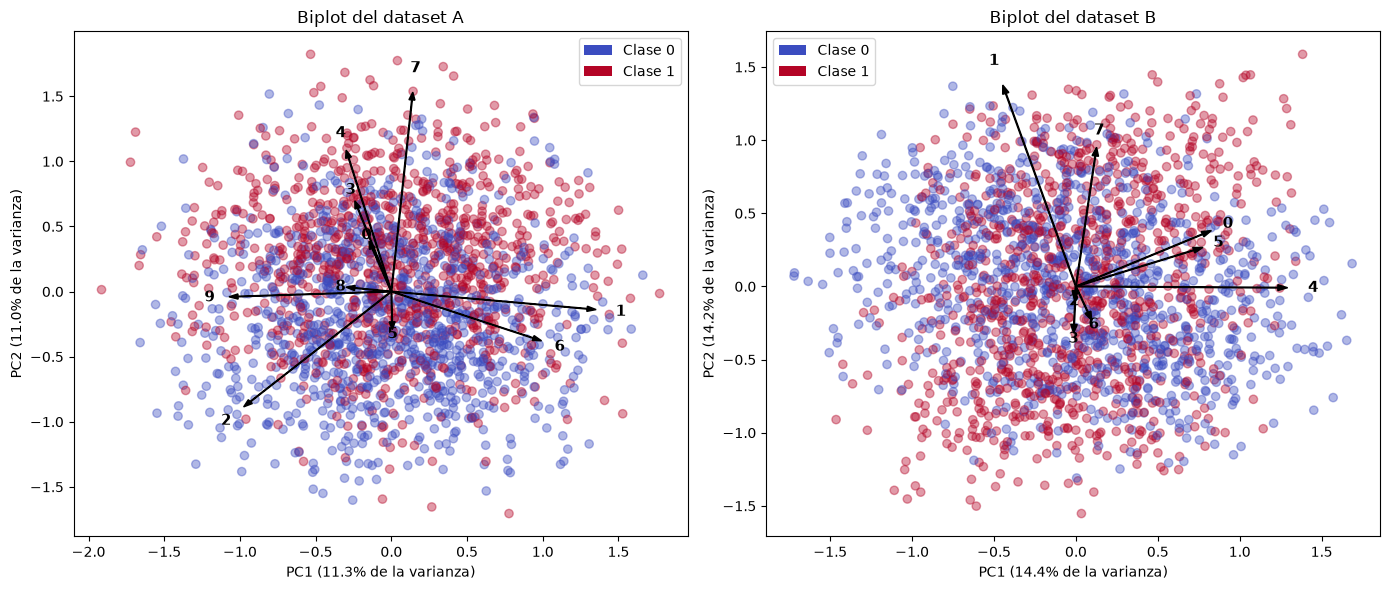

In [23]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Colores de las clases (-1 -> "Clase 0", 1 -> "Clase 1")
color_clase0, color_clase1 = plt.get_cmap("coolwarm")([0.0, 1.0])
cmap_clases = ListedColormap([color_clase0, color_clase1])
leyenda_clases = [
    Patch(facecolor=color_clase0, label="Clase 0"),
    Patch(facecolor=color_clase1, label="Clase 1")]

pca_a = PCA(n_components=2)
A_pca = pca_a.fit_transform(datosAX)
pca_b = PCA(n_components=2)
B_pca = pca_b.fit_transform(datosBX)

# A a la izquierda, B a la derecha
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 6))

for ax, X_pca, pca, y, nombre in [
        (ax_a, A_pca, pca_a, datosAy, "A"), (ax_b, B_pca, pca_b, datosBy, "B")]:
    ax.scatter(
        X_pca[:, 0], X_pca[:, 1], c=np.where(y == 1, 1, 0),
        cmap=cmap_clases, alpha=0.4)

    # flechas de las variables originales: la carga de cada variable en
    # PC1 y PC2, escalada para que se vea sobre la nube de puntos
    cargas = pca.components_.T  # (n_variables, 2)
    escala = np.abs(X_pca).max() / np.abs(cargas).max() * 0.8
    for j, (cx, cy) in enumerate(cargas):
        ax.arrow(0, 0, cx * escala, cy * escala, color='black',
                 width=0.005, head_width=0.04, length_includes_head=True)
        ax.text(cx * escala * 1.12, cy * escala * 1.12, str(j),
                fontsize=11, weight='bold', ha='center', va='center')

    var_exp = pca.explained_variance_ratio_
    ax.set_title(f"Biplot del dataset {nombre}")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1%} de la varianza)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1%} de la varianza)")
    ax.legend(handles=leyenda_clases)

plt.tight_layout()
plt.show()

Tanto para el dataset A como para el B, al usar PCA para proyectar los datos en dos componentes principales y visualizarlos, vemos una nube de puntos sin una clara separación entre clases.

Esto se debe a que los datos fueron generados usando ruido uniforme, con componentes independientes entre si. PCA maximiza la varianza, y en ambos casos la varianza es igual en todas las direcciones. La información relevante está en la relación que tienen los datos con la clase. Es por esto que aplicar PCA sobre los datos no nos aporta ningún valor.

## Análisis de los datasets con métodos de selección de variable

### Dataset A

In [16]:
frDatosA = forward_ranking(datosAX, datosAy, method=RF_error_estimation, 
                           total_trees=100, equalize_classes=False, verbosity=1)

brDatosA = backward_ranking(datosAX, datosAy, method=RF_error_estimation, 
                            total_trees=100, equalize_classes=False, verbosity=1)

krDatosA = kruskal_wallis_ranking(datosAX, datosAy)

rfeRFDatosA = recursive_feature_elimination_ranking(
    datosAX, datosAy, method=RF_ranking_method, total_trees=100,
    equalize_classes=False, verbosity=1)

rfeLSVMDatosA = recursive_feature_elimination_ranking(
    datosAX, datosAy, method=LSVM_ranking_method, verbosity=1)

print('Dataset A:')
print(f'Forward Ranking - (RF): \n{frDatosA}')
print(f'Backward Ranking - (RF): \n{brDatosA}')
print(f'Kruskal-Wallis Ranking: \n{krDatosA}')
print(f'Recursive Feature Elimination - (RF): \n{rfeRFDatosA}')
print(f'Recursive Feature Elimination - (LSVM): \n{rfeLSVMDatosA}')

Dataset A:
Forward Ranking - (RF): 
[7 5 8 9 6 4 3 1 2 0]
Backward Ranking - (RF): 
[7 5 8 1 0 6 2 4 3 9]
Kruskal-Wallis Ranking: 
[7 5 3 9 6 1 4 2 0 8]
Recursive Feature Elimination - (RF): 
[7 5 1 3 8 4 2 6 0 9]
Recursive Feature Elimination - (LSVM): 
[7 5 3 6 9 4 0 1 2 8]


El órden real de importancia de las variables es 7-5-3-1.
La primera define la clase del 50% de los datos, la segunda el 20%, la tercera el 10% y a cuarta e 5%. El resto de las variables no aportan información para predecir la clase.

Vemos que todos los métodos seleccionan las variables 7 y 5 como las más importantes, que es donde se define la clase del 70% de los datos.

Ahora, tanto Forward Ranking como Backward Ranking, usando como método de estima de error a Random Forest, no logran distinguir la importancia de la variable 3. Y ambos seleccionan a la variable 8 como importante, pero esto se da por casualidad, ya que no aporta informacion a la clase. 

Kruskal-Wallis funciona bien porque cada variable influye en la clase por separado. RFE también, porque la importancia en el modelo refleja ese efecto individual.

### Dataset B

In [23]:
frDatosB = forward_ranking(datosBX, datosBy, method=RF_error_estimation, 
                           total_trees=100, equalize_classes=False, verbosity=1)

brDatosB = backward_ranking(datosBX, datosBy, method=RF_error_estimation, 
                            total_trees=100, equalize_classes=False, verbosity=1)

krDatosB = kruskal_wallis_ranking(datosBX, datosBy)

rfeRFDatosB = recursive_feature_elimination_ranking(
    datosBX, datosBy, method=RF_ranking_method, total_trees=100,
    equalize_classes=False, verbosity=1)

rfeLSVMDatosB = recursive_feature_elimination_ranking(
    datosBX, datosBy, method=LSVM_ranking_method, verbosity=1)

print('Dataset B:')
print(f'Forward Ranking - (RF): \n{frDatosB}')
print(f'Backward Ranking - (RF): \n{brDatosB}')
print(f'Kruskal-Wallis Ranking: \n{krDatosB}')
print(f'Recursive Feature Elimination - (RF): \n{rfeRFDatosB}')
print(f'Recursive Feature Elimination - (LSVM): \n{rfeLSVMDatosB}')

Dataset B:
Forward Ranking - (RF): 
[0 1 6 3 7 2 5 4]
Backward Ranking - (RF): 
[0 1 7 6 3 4 2 5]
Kruskal-Wallis Ranking: 
[2 3 4 0 5 1 6 7]
Recursive Feature Elimination - (RF): 
[0 1 2 5 4 6 7 3]
Recursive Feature Elimination - (LSVM): 
[2 0 4 3 5 1 6 7]


Las variables 0 y 1 definen la clase, por lo que deberían ser las primeras seleccionadas. Aparte de esto, las variables 2 y 3 tienen un 50% de correlación con la clase. 

Forward y Backward ranking con Random Forest eligen correctamente las variables 0 y 1 como las más importantes. En el caso del Backward ranking, el proceso comienza con todas las variables elegidas, y se van removiendo una por una. Las últimas dos variables con las que se queda son la 0 y la 1, con las cuales puede predecir la clase para todos los datos. 


Pero en el caso del Forward Ranking, como se inicia con una única variable, y la clase está determinada por el XOR de la 0 y la 1, cualquier variable individual tiene la misma probabilidad de ser tomada como la primera. Es por esto que considero que considero que en este caso, se eligió a la variable 0 por casualidad, y el algorimo de Forward en su segunda iteración eligió correctamente a la 1, que era la que minimizaba el error.

En el caso de Kruskall-Wallis, como la elección se realiza sin considerar las variables en conjunto, el algoritmo ignoró las variables 0 y 1, y eligió la 2 y 3, que tienen el 50% de correlación con la clase de forma individual.

RFE con LSVM no obtuvo buenos resultados, dado que LSVM no es capaz de generar un hiperplano útil. 

RFE con RF en cambio, como los árboles pueden cortar primero por la variable 0 y después por la 1, logran resolver el problema del XOR.

In [25]:
d = 8
n = 1000
datosBX, datosBy = crea_ruido_unif(n=n, d=d)
datosBy = np.sign(datosBX[:, 0] * datosBX[:, 1])
shuffle = np.random.permutation(len(datosBy))
sub = shuffle[:int(len(datosBy) * 0.5)]
datosBX[sub, 2] = np.abs(datosBX[sub, 2] * datosBy[sub])
shuffle = np.random.permutation(len(datosBy))
sub = shuffle[:int(len(datosBy) * 0.5)]
datosBX[sub, 3] = np.abs(datosBX[sub, 3] * datosBy[sub])

frDatosB = forward_ranking(datosBX, datosBy, method=RF_error_estimation,
                            total_trees=100, equalize_classes=False)

print(f'Forward Ranking (RF): {frDatosB}')

Forward Ranking (RF): [4 3 0 1 7 5 2 6]


Regenerando los datos vemos que efectivamente, el Foward Ranking anterior estaba seleccionando el 0 como primer valor de casualidad. 

# Ejercicio 3

In [13]:

from typing import Tuple
import pandas as pd

def diagonal(d: int, C: float, n: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Genera sampleos de dos gausianas d-dimensionales en posición diagonal
    (una respecto a la otra), con dispersión C * sqrt(d).
    Cada sampleo posee n/2 puntos.

    Argumentos:
        d: número de dimensiones
        C: constante de ajuste de dispersión

    Retorna:
        X: matriz con d columnas y n filas de datos
        y: arreglo de n elementos con las clases correspondientes
            a cada fila de datos
    """
    data1 = np.random.multivariate_normal(np.full(d, -1) , np.diag([(C * np.sqrt(d))**2]*d), n//2)
    data2 = np.random.multivariate_normal(np.full(d, 1) , np.diag([(C * np.sqrt(d))**2]*d), n//2)
    data = [[0, *x] for x in data1] + [[1, *x] for x in data2]
    df = pd.DataFrame(data, columns=(['Clase'] + ['d' + str(x + 1) for x in range(d)]))

    X = df.iloc[:, 1:].to_numpy()
    y = df.iloc[:, 0].to_numpy()
    return X, y

In [21]:
variables = 10
puntos = 100
C = 2
reps = 30
results = []
metodos = ['Forward (RF)', 'Backward (RF)', 'Kruskal-Wallis', 'RFE (RF)', 'RFE (LSVM)']

for i in range(reps):

    dpreX, dY = diagonal(variables, C, puntos)
    X_ruido = np.random.normal(0, C * np.sqrt(variables), size=(puntos, 90))
    dX= np.hstack([dpreX, X_ruido])

    frDatosX = forward_ranking(dX, dY, method=RF_error_estimation, 
                            total_trees=100, equalize_classes=False, verbosity=0)

    brDatosX = backward_ranking(dX, dY, method=RF_error_estimation, 
                                total_trees=100, equalize_classes=False, verbosity=0)

    krDatosX = kruskal_wallis_ranking(dX, dY)

    rfeRFDatosX = recursive_feature_elimination_ranking(
        dX, dY, method=RF_ranking_method, total_trees=100,
        equalize_classes=False, verbosity=0)

    rfeLSVMDatosX = recursive_feature_elimination_ranking(
        dX, dY, method=LSVM_ranking_method, verbosity=0)

    results.append((frDatosX, brDatosX, krDatosX, rfeRFDatosX, rfeLSVMDatosX))

/home/bruno/miniconda3/envs/tmd/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/bruno/miniconda3/envs/tmd/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/bruno/miniconda3/envs/tmd/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/bruno/miniconda3/envs/tmd/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/bruno/miniconda3/envs/tmd/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/bruno/miniconda3/envs/tmd/lib/python3.12/sit

In [28]:
# Análisis de los resultados:
for i, metodo in enumerate(metodos):
    aciertos = [np.sum(np.array(r[i])[:10] < 10) for r in results]
    print(f'{metodo}: {np.mean(aciertos) * 10:.2f}% de aciertos')

Forward (RF): 15.67% de aciertos
Backward (RF): 13.00% de aciertos
Kruskal-Wallis: 37.67% de aciertos
RFE (RF): 32.67% de aciertos
RFE (LSVM): 26.67% de aciertos


En el problema de la diagonal, las variables no estan correlacionadas. Es por esto que los métodos univariados tienen ventaja con respecto a los multivariados.
Vemos esto reflejado en los resultados con Kruskall-Wallis, que tiene el mayor porcentaje de acierto en la selección de variables en las 30 corridas. 

Observamos que con eliminación recursiva de features, random forest tiene un mejor desempeño que LSVM. Esto resulta contraintuitivo, ya que al ser un problema lineal, LSVM debería tener un mejor desempeño. Esto puede deberse a que random forest promedia la importancia de las variables sobre muchos árboles entrenados con distintos subjconjuntos de datos y variables, lo que lo hace más estable frente a una grán cantidad de variables que solo aportan ruido.

Por ultimo vemos, como se esperaba, que los métodos de forwad y backward tienen el peor desempeño. El hecho de que forward supere a backward se debe a que al haber 100 variables, la diferencia que se produce en el error al sacar una es casi imperceptible. 


# Ejercicio 4

Repetición 1: top 10 = [10 11 51  8  9 50 16 48  3 22]
Repetición 2: top 10 = [10  8 11 48 47 35 44 51  9 46]
Repetición 3: top 10 = [11 10 19 46  8  9 20 26 48 15]
Repetición 4: top 10 = [10 11 46  8 35 20  9 19 44 12]
Repetición 5: top 10 = [11 10 47  8  9 16 19 46 51 44]


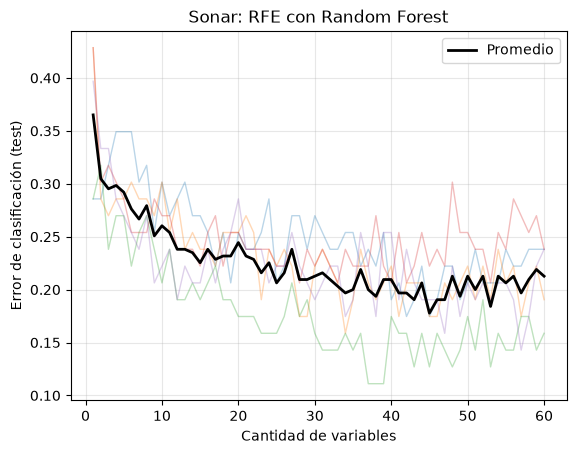

Mínimo error promedio: 0.178 con 45 variables
Error con las 60 variables: 0.213


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split

sonar = pd.read_csv('sonar.csv', header=None)
X = sonar.iloc[:, :-1].to_numpy()
y = sonar.iloc[:, -1].to_numpy()

repeticiones = 5
n_feat = X.shape[1]
errores = np.zeros((repeticiones, n_feat))

for rep in range(repeticiones):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=rep)

    ranking = recursive_feature_elimination_ranking(
        X_train, y_train, method=RF_ranking_method, total_trees=100)

    # error en test usando las k mejores variables
    for k in range(1, n_feat + 1):
        feats = ranking[:k]
        rf = RandomForestClassifier(n_estimators=100)
        rf.fit(X_train[:, feats], y_train)
        errores[rep, k - 1] = 1 - rf.score(X_test[:, feats], y_test)

    print(f'Repetición {rep + 1}: top 10 = {ranking[:10]}')

media = errores.mean(axis=0)
k_vals = np.arange(1, n_feat + 1)

for rep in range(repeticiones):
    plt.plot(k_vals, errores[rep], alpha=0.3, lw=1)
plt.plot(k_vals, media, color='black', lw=2, label='Promedio')
plt.xlabel('Cantidad de variables')
plt.ylabel('Error de clasificación (test)')
plt.title('Sonar: RFE con Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f'Mínimo error promedio: {media.min():.3f} con {np.argmin(media) + 1} variables')
print(f'Error con las 60 variables: {media[-1]:.3f}')


Mostramos las primeras 10 variables seleccionadas para cada iteración usando RFE con RF, y vemos que en general se repite el mismo conjunto de variables, lo que nos indica que existe un conjunto de variables específico que determina la clase.

Para visualizar cuantas de estas variables son necesarias, graficamos la curva de error vs features para las 5 corridas, y graficamos el error promedio de las corridas para cada cantidad de variables. 

Esto nos indica que en promedio, el error mínimo de todas las corridas esta en 0.178, con 45 variables.

Cabe destacar que los resultados individuales oscilan mucho pasadas las 30 varibales, por lo que es posible que realizando una mayor cantidad de corridas se llegue a un umbral de variables útiles más exacto.

# Ejercicio 5

Para este ejercicio se eligió el dataset "Human Activity Recognition with Smartphones", el cuál registra mediciones de los sensores de los celulares de los participantes mientras realizan distintas tareas tales como caminar, estar levantados, sentados o acostados.

[Link de descarga del dataset](https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones?resource=download)

In [14]:
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

activity = pd.read_csv('activity.csv')
X_act = activity.drop(columns=['subject', 'Activity']).to_numpy()
y_act = activity['Activity'].to_numpy()
sujetos = activity['subject'].to_numpy()
nombres_act = activity.columns[:-2].to_numpy()

print(f'Shape: {X_act.shape}')
print(activity['Activity'].value_counts())
print(f'Sujetos: {np.unique(sujetos)}')

Shape: (2947, 561)
Activity
LAYING                537
STANDING              532
WALKING               496
SITTING               491
WALKING_UPSTAIRS      471
WALKING_DOWNSTAIRS    420
Name: count, dtype: int64
Sujetos: [ 2  4  9 10 12 13 18 20 24]


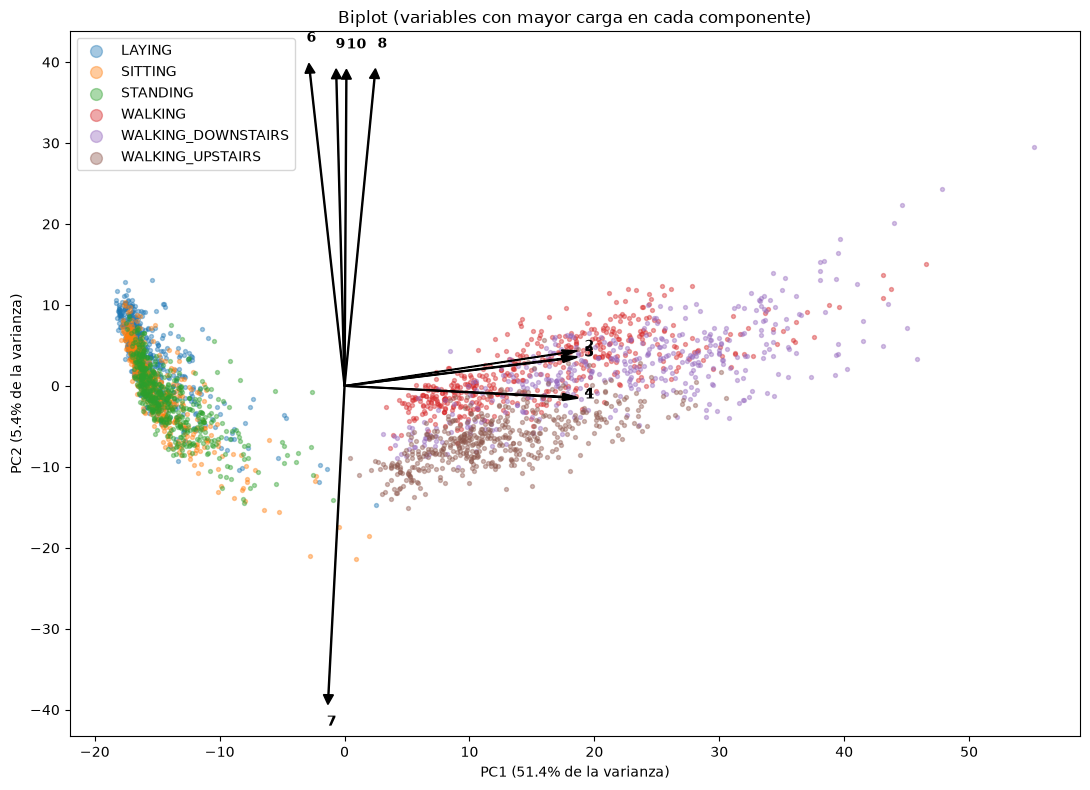

 1. fBodyAcc-sma()                      PC1=+0.058  PC2=-0.005
 2. fBodyAccJerk-sma()                  PC1=+0.058  PC2=+0.014
 3. tBodyAccJerk-sma()                  PC1=+0.058  PC2=+0.011
 4. fBodyGyro-sma()                     PC1=+0.058  PC2=-0.004
 5. tBodyAccJerkMag-mean()              PC1=+0.058  PC2=+0.011
 6. fBodyAcc-meanFreq()-Z               PC1=-0.009  PC2=+0.129
 7. tGravityAcc-arCoeff()-Z,2           PC1=-0.004  PC2=-0.127
 8. tGravityAcc-arCoeff()-Z,1           PC1=+0.008  PC2=+0.127
 9. fBodyAccMag-meanFreq()              PC1=-0.002  PC2=+0.127
10. tGravityAcc-arCoeff()-Z,3           PC1=+0.000  PC2=+0.126


In [15]:
# Biplot
X_std = StandardScaler().fit_transform(X_act)
pca_act = PCA(n_components=2)
X_act_pca = pca_act.fit_transform(X_std)

# con 561 variables no se pueden dibujar todas las flechas
n_por_eje = 5
cargas = pca_act.components_.T  # (n_variables, 2)
top_pc1 = np.argsort(-np.abs(cargas[:, 0]))[:n_por_eje]
top_pc2 = np.argsort(-np.abs(cargas[:, 1]))[:n_por_eje]
top = np.concatenate([top_pc1, top_pc2])
escala = np.abs(X_act_pca).max() / np.abs(cargas[top]).max() * 0.7

fig, ax = plt.subplots(figsize=(11, 8))
actividades = np.unique(y_act)
colores = plt.get_cmap('tab10')(np.arange(len(actividades)))
for act, color in zip(actividades, colores):
    mask = y_act == act
    ax.scatter(X_act_pca[mask, 0], X_act_pca[mask, 1],
               s=8, alpha=0.4, color=color, label=act)
for num, j in enumerate(top, start=1):
    dx, dy = cargas[j] * escala
    ax.arrow(0, 0, dx, dy, color='black', width=0.08, head_width=0.8)
    ax.text(dx * 1.1, dy * 1.1, str(num), fontsize=10, weight='bold')
var_exp = pca_act.explained_variance_ratio_
ax.set_xlabel(f'PC1 ({var_exp[0]:.1%} de la varianza)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.1%} de la varianza)')
ax.set_title('Biplot (variables con mayor carga en cada componente)')
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

for num, j in enumerate(top, start=1):
    print(f'{num:2d}. {nombres_act[j]:35s} PC1={cargas[j, 0]:+.3f}  PC2={cargas[j, 1]:+.3f}')


Graficamos el PCA junto con las variables originales más importantes para cada componente.

La variables del 1 al 5 son los sensores que miden el movimiento, los cambios en la aceleración, el giro y rotación del celular. Estas son las más importantes en la primera componente, y permiten distinguir perfectamente el conjunto de actividades estáticas (estar sentado, acostado o parado) de las actividades dinámicas (caminar, subir y bajar escaleras). 

En el otro eje tenemos las variables del 6 al 10, que son los sensores que miden la frecuencia del movimiento vertical, coeficientes relacionados con la gravedad y la frecuencia promedio del movimiento. Vemos que esta componente tiene una varianza mucho menor que PC1 (5.4% contra 51.4%) por lo que logra una menor separación de las clases. Pero aún así, con ayuda del gráfico, podemos ver que se separan las clases de la caminata hacia abajo, hacia arriba, y la caminata común. Y por el otro lado, también logra un poco de separación entre el estar acostado, sentado o parado.

También podemos notar que hay muchas flechas que apuntan casi al mismo lugar, lo que implica que las variables están altamente correlacionadas, indicando un grán grado de redundancia en el dataset.



In [18]:
# Selección de variables y error vs cantidad de variables
repeticiones = 5
# no evalúo las 561 cantidades posibles: denso al principio, espaciado después
k_vals = np.unique(np.concatenate([
    np.arange(1, 21), np.geomspace(20, X_act.shape[1], 15).astype(int)]))

def rfe_lsvm_ranking(X, y):
    return recursive_feature_elimination_ranking(
        X, y, method=LSVM_ranking_method, C=1)


metodos_act = {
    'RFE (LSVM)': rfe_lsvm_ranking,
    'Kruskal-Wallis': kruskal_wallis_ranking,
}
errores_act = {m: np.zeros((repeticiones, len(k_vals))) for m in metodos_act}
rankings_act = {m: [] for m in metodos_act}

gss = GroupShuffleSplit(n_splits=repeticiones, test_size=3, random_state=0)

for rep, (idx_train, idx_test) in enumerate(gss.split(X_act, y_act, sujetos)):
    X_train, X_test = X_act[idx_train], X_act[idx_test]
    y_train, y_test = y_act[idx_train], y_act[idx_test]

    for metodo, ranking_fn in metodos_act.items():
        ranking = ranking_fn(X_train, y_train)
        rankings_act[metodo].append(ranking)

        for i, k in enumerate(k_vals):
            feats = ranking[:k]
            svm = LinearSVC(C=1)
            svm.fit(X_train[:, feats], y_train)
            errores_act[metodo][rep, i] = 1 - svm.score(X_test[:, feats], y_test)

        print(f'Rep {rep + 1} - {metodo}, sujetos test {np.unique(sujetos[idx_test])}: '
              f'top 5 = {list(nombres_act[ranking[:5]])}')


Rep 1 - RFE (LSVM), sujetos test [ 4  9 20]: top 5 = ['tGravityAcc-energy()-X', 'angle(X,gravityMean)', 'tGravityAcc-mean()-X', 'fBodyAcc-std()-X', 'tBodyAccJerkMag-iqr()']
Rep 1 - Kruskal-Wallis, sujetos test [ 4  9 20]: top 5 = ['fBodyAcc-bandsEnergy()-1,8', 'fBodyAcc-max()-X', 'fBodyAccJerk-entropy()-X', 'fBodyBodyAccJerkMag-entropy()', 'fBodyAccJerk-entropy()-Z']
Rep 2 - RFE (LSVM), sujetos test [ 4 10 20]: top 5 = ['fBodyAccMag-energy()', 'fBodyAccJerk-bandsEnergy()-33,48.2', 'tGravityAcc-mean()-X', 'tGravityAcc-max()-Y', 'tGravityAcc-energy()-X']
Rep 2 - Kruskal-Wallis, sujetos test [ 4 10 20]: top 5 = ['fBodyAcc-bandsEnergy()-1,8', 'fBodyAccJerk-entropy()-X', 'fBodyAcc-max()-X', 'fBodyAcc-bandsEnergy()-1,16', 'fBodyAcc-std()-X']
Rep 3 - RFE (LSVM), sujetos test [ 9 10 13]: top 5 = ['tBodyAccJerkMag-iqr()', 'fBodyAccMag-std()', 'tGravityAcc-min()-Y', 'tGravityAcc-energy()-Y', 'fBodyAcc-std()-X']
Rep 3 - Kruskal-Wallis, sujetos test [ 9 10 13]: top 5 = ['fBodyAcc-bandsEnergy()-1,8

Se realizaron 5 repeticiones de selección de variable usando RFE con LSVM, y otras 5 usando Kruskal-Wallis. Encontramos que cada método tiene a elegir variables de distinta naturaleza.

En cada repetición se separaron los datos en train y test por persona: se tomaron 3 de los 9 sujetos para test y el resto para train. Esto es necesario porque las mediciones consecutivas de una misma persona son casi iguales entre sí.

Como Kruskall-Wallis es un método univariado elige una por una las variables que mejor separan de manera individual las actividades estáticas de las dinámicas, siendo estas las relacionadas con la aceleración.

RFE en cambio, combina variables de movimiento junto con variables de orientación respecto a la gravedad. Esto indica la postura del cuerpo, por lo que permite distinguir entre acostado, sentado o parado. Esto es algo que la variable de aceleracion no puede hacer de forma independiente.

RFE (LSVM): mínimo error promedio 0.116 con 134 variables; con todas: 0.120
Kruskal-Wallis: mínimo error promedio 0.121 con 561 variables; con todas: 0.121


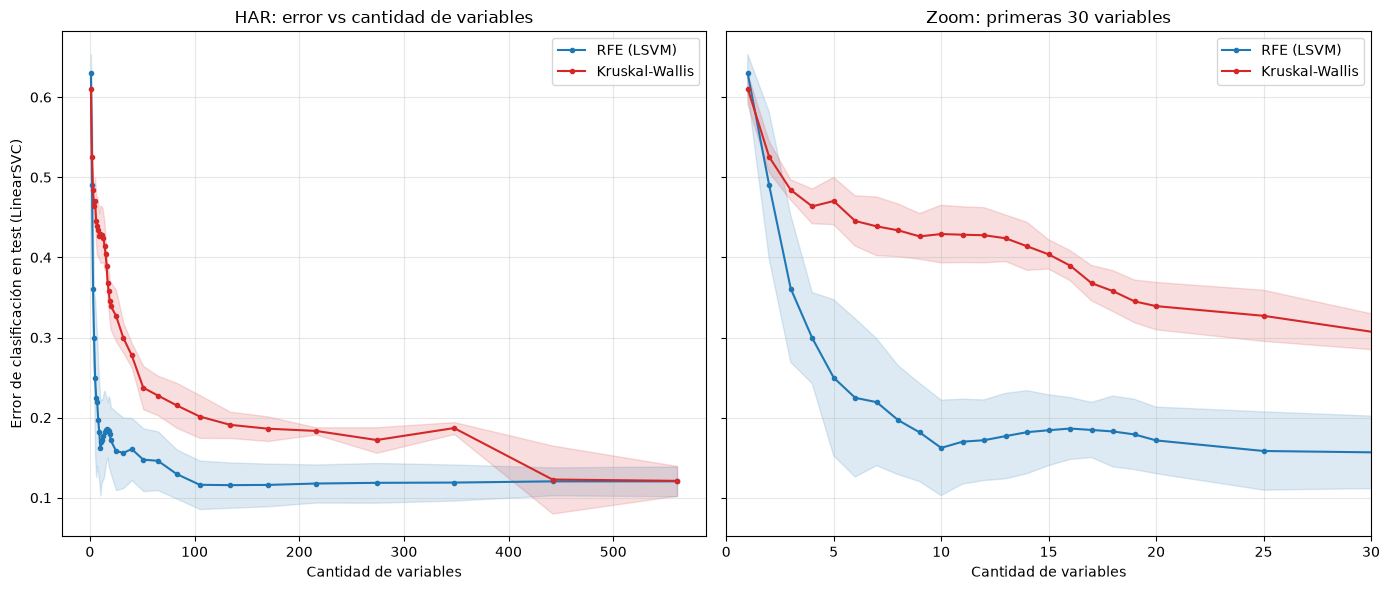

In [19]:
# Curva de error 
# a la izquierda la curva completa, a la derecha un zoom en las primeras variables
fig, (ax_todo, ax_zoom) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
k_zoom = 30
for (metodo, errores), color in zip(errores_act.items(), ['C0', 'C3']):
    media = errores.mean(axis=0)
    desvio = errores.std(axis=0)
    for ax in (ax_todo, ax_zoom):
        ax.plot(k_vals, media, marker='o', ms=3, color=color, label=metodo)
        ax.fill_between(k_vals, media - desvio, media + desvio, color=color, alpha=0.15)
    print(f'{metodo}: mínimo error promedio {media.min():.3f} con '
          f'{k_vals[np.argmin(media)]} variables; con todas: {media[-1]:.3f}')
ax_zoom.set_xlim(0, k_zoom)
ax_todo.set_title('HAR: error vs cantidad de variables')
ax_zoom.set_title(f'Zoom: primeras {k_zoom} variables')
ax_todo.set_ylabel('Error de clasificación en test (LinearSVC)')
for ax in (ax_todo, ax_zoom):
    ax.set_xlabel('Cantidad de variables')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Graficamos la curva de error medio según la cantidad de variables para los dos métodos de selección de variable utilizados, haciendo foco en las primeras 30, que es cuando se produce una mayor disminución del error.

Vemos que el error de RFE disminuye rápidamente, llegando cerca del 0.15 con 10 variables, y bajando hasta un 0.116 con 134. Este error se mantiene relativamente igual sumando el resto de las variables, por lo que podemos decir que el 75% de las variables registradas en el dataset no son necesarias para determinar la actividad.

El error usando Kruskall-Wallis baja mucho más lento, y recién logra alcanzar al depempeño de RFE con 400 variables. Esto se puede explicar con lo visto en el biplot del PCA, con el hecho de que muchas de las variables que están primeras en el ranking estan correlacionadas.